<a href="https://colab.research.google.com/github/ounissinour/PolypVision/blob/main/notebooks/01_PraNet_Reproduction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi
import torch
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Sat Oct 17 11:47:24 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%cd /content
!git clone https://github.com/DengPingFan/PraNet.git
%cd PraNet

/content
Cloning into 'PraNet'...
remote: Enumerating objects: 1021, done.
remote: Counting objects: 100% (134/134), done.
remote: Compressing objects: 100% (76/76), done.
remote: Total 1021 (delta 93), reused 79 (delta 58), pack-reused 887 (from 1)
Receiving objects: 100% (1021/1021), 13.23 MiB | 36.72 MiB/s, done.
Resolving deltas: 100% (180/180), done.
/content/PraNet


In [ ]:
!pip install -q opencv-python scipy imageio tqdm

In [ ]:
import os
base = '/content/drive/MyDrive/PolypVision'
for d in ['data/TestDataset', 'checkpoints', 'results/pranet']:
    os.makedirs(f'{base}/{d}', exist_ok=True)
print(os.listdir(base))

['notebooks', 'datasets', 'checkpoints', 'predictions', 'results', 'docs', 'data']


In [ ]:
!mkdir -p /content/PraNet/snapshots/PraNet_Res2Net
!cp /content/drive/MyDrive/PolypVision/checkpoints/PraNet-19.pth /content/PraNet/snapshots/PraNet_Res2Net/
!mkdir -p /content/PraNet/data
!cp -r /content/drive/MyDrive/PolypVision/data/TestDataset /content/PraNet/data/
!ls -lh /content/PraNet/snapshots/PraNet_Res2Net/
!ls /content/PraNet/data/TestDataset

total 125M
-rw------- 1 root root 125M Oct 17 12:36 PraNet-19.pth
CVC-300  CVC-ClinicDB  CVC-ColonDB  ETIS-LaribPolypDB  Kvasir


In [ ]:
%cd /content/PraNet
!cat MyTest.py

/content/PraNet
import torch
import torch.nn.functional as F
import numpy as np
import os, argparse
from scipy import misc
from lib.PraNet_Res2Net import PraNet
from utils.dataloader import test_dataset

parser = argparse.ArgumentParser()
parser.add_argument('--testsize', type=int, default=352, help='testing size')
parser.add_argument('--pth_path', type=str, default='./snapshots/PraNet_Res2Net/PraNet-19.pth')

for _data_name in ['CVC-300', 'CVC-ClinicDB', 'Kvasir', 'CVC-ColonDB', 'ETIS-LaribPolypDB']:
    data_path = './data/TestDataset/{}/'.format(_data_name)
    save_path = './results/PraNet/{}/'.format(_data_name)
    opt = parser.parse_args()
    model = PraNet()
    model.load_state_dict(torch.load(opt.pth_path))
    model.cuda()
    model.eval()

    os.makedirs(save_path, exist_ok=True)
    image_root = '{}/images/'.format(data_path)
    gt_root = '{}/masks/'.format(data_path)
    test_loader = test_dataset(image_root, gt_root, opt.testsize)

    for i in range(test_loader.size)

In [ ]:
%cd /content/PraNet
!sed -i 's/from scipy import misc/import imageio/' MyTest.py
!sed -i 's/misc.imsave(save_path+name, res)/imageio.imwrite(save_path+name, (res*255).astype(np.uint8))/' MyTest.py
!sed -i "s/torch.load(opt.pth_path)/torch.load(opt.pth_path, map_location='cuda', weights_only=True)/" MyTest.py
!sed -i 's/F.upsample/F.interpolate/' MyTest.py
!grep -n "imageio\|torch.load\|interpolate" MyTest.py

/content/PraNet
5:import imageio
18:    model.load_state_dict(torch.load(opt.pth_path, map_location='cuda', weights_only=True))
35:        res = F.interpolate(res, size=gt.shape, mode='bilinear', align_corners=False)
38:        imageio.imwrite(save_path+name, (res*255).astype(np.uint8))


In [ ]:
!python MyTest.py --pth_path './snapshots/PraNet_Res2Net/PraNet-19.pth'

Traceback (most recent call last):
  File "/content/PraNet/MyTest.py", line 17, in <module>
    model = PraNet()
  File "/content/PraNet/lib/PraNet_Res2Net.py", line 103, in __init__
    self.resnet = res2net50_v1b_26w_4s(pretrained=True)
                  ~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/content/PraNet/lib/Res2Net_v1b.py", line 195, in res2net50_v1b_26w_4s
    model_state = torch.load('/media/nercms/NERCMS/GepengJi/Medical_Seqmentation/CRANet/models/res2net50_v1b_26w_4s-3cf99910.pth')
  File "/usr/local/lib/python3.13/dist-packages/torch/serialization.py", line 1530, in load
    with _open_file_like(f, "rb") as opened_file:
         ~~~~~~~~~~~~~~~^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/serialization.py", line 795, in _open_file_like
    return _open_file(name_or_buffer, mode)
  File "/usr/local/lib/python3.13/dist-packages/torch/serialization.py", line 776, in __init__
    super().__init__(open(name, mode))  # noqa: SIM115
                     ~~

In [ ]:
%cd /content/PraNet
!sed -i 's/res2net50_v1b_26w_4s(pretrained=True)/res2net50_v1b_26w_4s(pretrained=False)/' lib/PraNet_Res2Net.py
!grep -n "pretrained" lib/PraNet_Res2Net.py

/content/PraNet
103:        self.resnet = res2net50_v1b_26w_4s(pretrained=False)


In [ ]:
%cd /content/PraNet
# 1. Res2Net backbone bla pretrained (el weights mawjoudin fil PraNet-19.pth)
!sed -i 's/res2net50_v1b_26w_4s(pretrained=True)/res2net50_v1b_26w_4s(pretrained=False)/' lib/PraNet_Res2Net.py
# 2. Sala7 MyTest.py (scipy, torch.load, upsample)
!sed -i 's/from scipy import misc/import imageio/' MyTest.py
!sed -i 's/misc.imsave(save_path+name, res)/imageio.imwrite(save_path+name, (res*255).astype(np.uint8))/' MyTest.py
!sed -i "s/torch.load(opt.pth_path)/torch.load(opt.pth_path, map_location='cuda', weights_only=True)/" MyTest.py
!sed -i 's/F.upsample/F.interpolate/' MyTest.py
# Verifi
!grep -n "pretrained" lib/PraNet_Res2Net.py
!grep -n "imageio\|torch.load\|interpolate" MyTest.py

/content/PraNet
103:        self.resnet = res2net50_v1b_26w_4s(pretrained=False)
5:import imageio
18:    model.load_state_dict(torch.load(opt.pth_path, map_location='cuda', weights_only=True))
35:        res = F.interpolate(res, size=gt.shape, mode='bilinear', align_corners=False)
38:        imageio.imwrite(save_path+name, (res*255).astype(np.uint8))


In [ ]:
!python MyTest.py --pth_path './snapshots/PraNet_Res2Net/PraNet-19.pth'

In [ ]:
!ls /content/PraNet/results/PraNet/Kvasir | wc -l
!ls /content/PraNet/results/PraNet/CVC-ClinicDB | wc -l

100
62


In [ ]:
##saving predictions in drive
!mkdir -p /content/drive/MyDrive/PolypVision/results/pranet
!cp -r /content/PraNet/results/PraNet/* /content/drive/MyDrive/PolypVision/results/pranet/
!ls /content/drive/MyDrive/PolypVision/results/pranet

CVC-300  CVC-ClinicDB  CVC-ColonDB  ETIS-LaribPolypDB  Kvasir


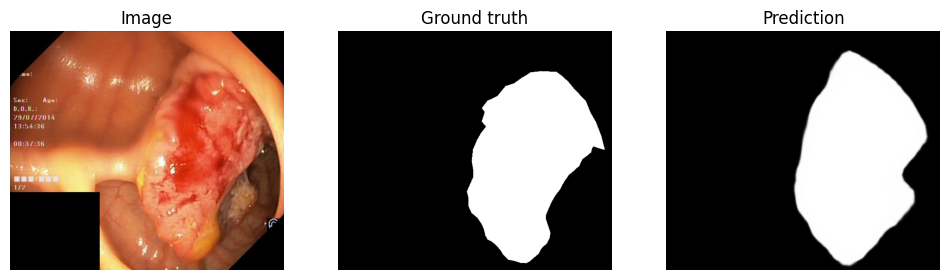

In [ ]:
import cv2, matplotlib.pyplot as plt
name = sorted(os.listdir('/content/PraNet/results/PraNet/Kvasir'))[0]
img = cv2.imread(f'/content/PraNet/data/TestDataset/Kvasir/images/{name}')[:,:,::-1]
gt  = cv2.imread(f'/content/PraNet/data/TestDataset/Kvasir/masks/{name}', 0)
pr  = cv2.imread(f'/content/PraNet/results/PraNet/Kvasir/{name}', 0)
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, im, t in zip(ax, [img, gt, pr], ['Image', 'Ground truth', 'Prediction']):
    a.imshow(im, cmap=None if t == 'Image' else 'gray'); a.set_title(t); a.axis('off')
plt.show()

In [ ]:
import numpy as np, cv2, os, pandas as pd

def dice_iou(pred, gt, thr=0.5, eps=1e-8):
    p = (pred / 255.0) >= thr
    g = (gt / 255.0) >= 0.5
    inter = np.logical_and(p, g).sum()
    dice = (2 * inter + eps) / (p.sum() + g.sum() + eps)
    iou  = (inter + eps) / (np.logical_or(p, g).sum() + eps)
    return dice, iou

def evaluate(dataset, pred_root, gt_root):
    rows = []
    for name in sorted(os.listdir(pred_root)):
        pr = cv2.imread(os.path.join(pred_root, name), 0)
        gt = cv2.imread(os.path.join(gt_root, name), 0)
        d, i = dice_iou(pr, gt)
        rows.append(dict(model='PraNet', dataset=dataset, image=name, dice=d, iou=i))
    return pd.DataFrame(rows)

dfs = []
for ds in ['Kvasir', 'CVC-ClinicDB']:
    dfs.append(evaluate(ds,
        f'/content/PraNet/results/PraNet/{ds}',
        f'/content/PraNet/data/TestDataset/{ds}/masks'))
df = pd.concat(dfs)
print(df.groupby('dataset')[['dice', 'iou']].mean().round(4))

                dice     iou
dataset                     
CVC-ClinicDB  0.9052  0.8575
Kvasir        0.8993  0.8427


In [ ]:
os.makedirs('/content/drive/MyDrive/PolypVision/results', exist_ok=True)
df.to_csv('/content/drive/MyDrive/PolypVision/results/pranet_metrics.csv', index=False)

In [ ]:
import pandas as pd

res = df.groupby('dataset')[['dice', 'iou']].mean().round(4)

# Arqam el paper: THABBET menhom fil Table mta3 arxiv 2006.11392 9bal ma testa3mlhom
paper = {
    'Kvasir':       {'dice': 0.898, 'iou': 0.840},
    'CVC-ClinicDB': {'dice': 0.899, 'iou': 0.849},
}

table = pd.DataFrame({
    'Dice (reproduced)': res['dice'],
    'Dice (paper)':      pd.Series({k: v['dice'] for k, v in paper.items()}),
    'IoU (reproduced)':  res['iou'],
    'IoU (paper)':       pd.Series({k: v['iou'] for k, v in paper.items()}),
})
table['Dice diff'] = (table['Dice (reproduced)'] - table['Dice (paper)']).round(4)
table['IoU diff']  = (table['IoU (reproduced)']  - table['IoU (paper)']).round(4)
print(table)

table.to_csv('/content/drive/MyDrive/PolypVision/results/pranet_vs_paper.csv')

              Dice (reproduced)  Dice (paper)  IoU (reproduced)  IoU (paper)  \
CVC-ClinicDB             0.9052         0.899            0.8575        0.849   
Kvasir                   0.8993         0.898            0.8427        0.840   

              Dice diff  IoU diff  
CVC-ClinicDB     0.0062    0.0085  
Kvasir           0.0013    0.0027  


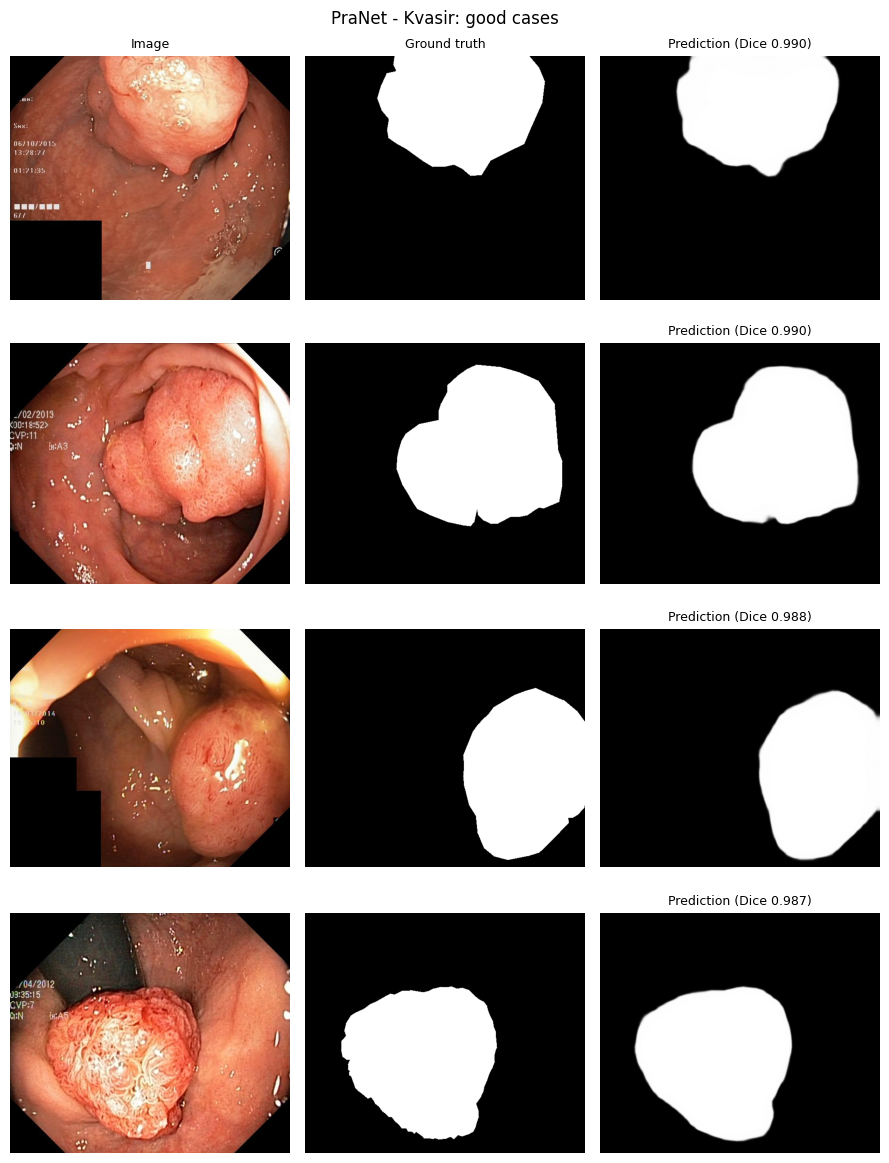

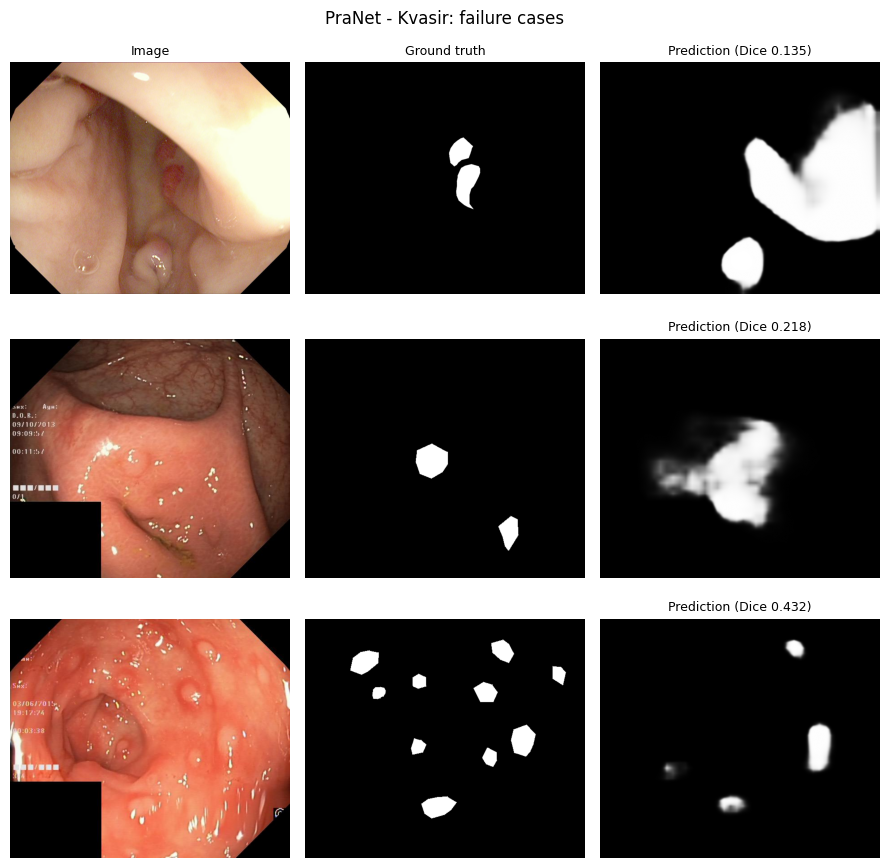

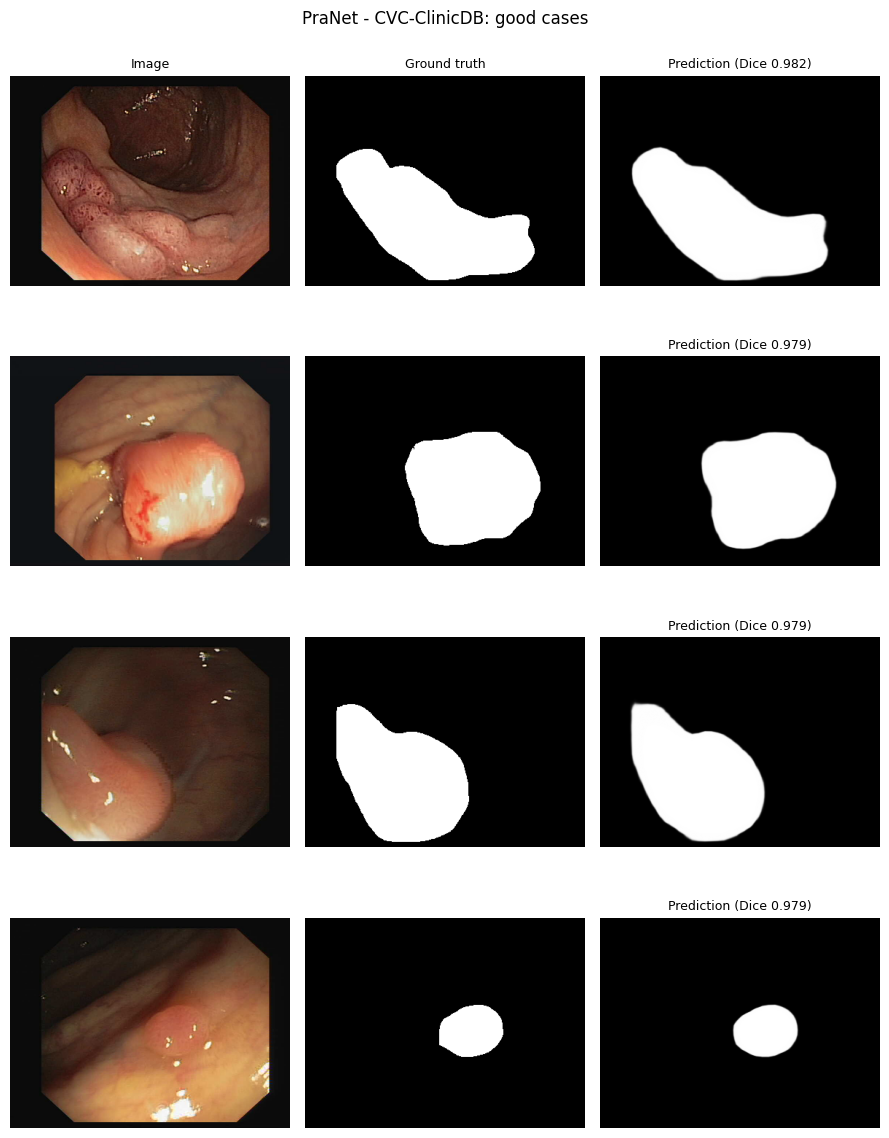

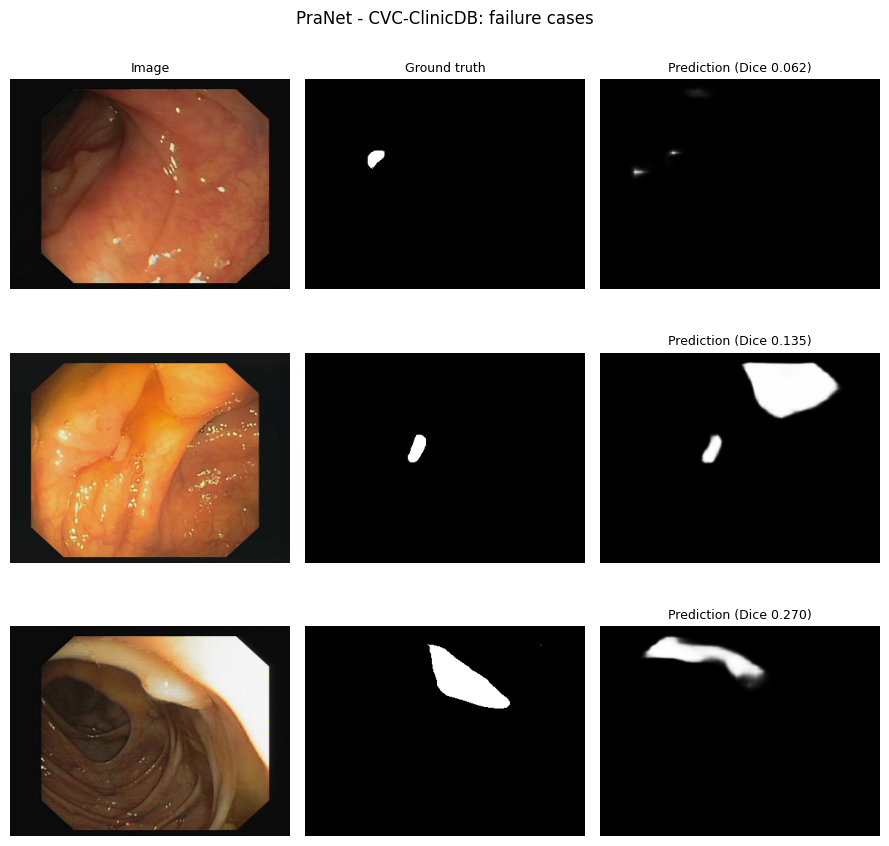

In [42]:
import os, cv2, matplotlib.pyplot as plt

def show_cases(dataset, names, dices, title, out_path):
    fig, ax = plt.subplots(len(names), 3, figsize=(9, 3 * len(names)))
    for r, (name, d) in enumerate(zip(names, dices)):
        img = cv2.imread(f'/content/PraNet/data/TestDataset/{dataset}/images/{name}')[:, :, ::-1]
        gt  = cv2.imread(f'/content/PraNet/data/TestDataset/{dataset}/masks/{name}', 0)
        pr  = cv2.imread(f'/content/PraNet/results/PraNet/{dataset}/{name}', 0)
        for c, (im, t) in enumerate(zip([img, gt, pr], ['Image', 'Ground truth', f'Prediction (Dice {d:.3f})'])):
            ax[r, c].imshow(im, cmap=None if c == 0 else 'gray')
            ax[r, c].axis('off')
            if r == 0 or c == 2:
                ax[r, c].set_title(t if r == 0 else t, fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    plt.savefig(out_path, dpi=200, bbox_inches='tight')
    plt.show()

out = '/content/drive/MyDrive/PolypVision/figures'
for ds in ['Kvasir', 'CVC-ClinicDB']:
    d = df[df.dataset == ds]
    best  = d.sort_values('dice', ascending=False).head(4)
    worst = d.sort_values('dice').head(3)
    show_cases(ds, best.image.tolist(),  best.dice.tolist(),  f'PraNet - {ds}: good cases',    f'{out}/pranet_{ds}_good.png')
    show_cases(ds, worst.image.tolist(), worst.dice.tolist(), f'PraNet - {ds}: failure cases', f'{out}/pranet_{ds}_failures.png')

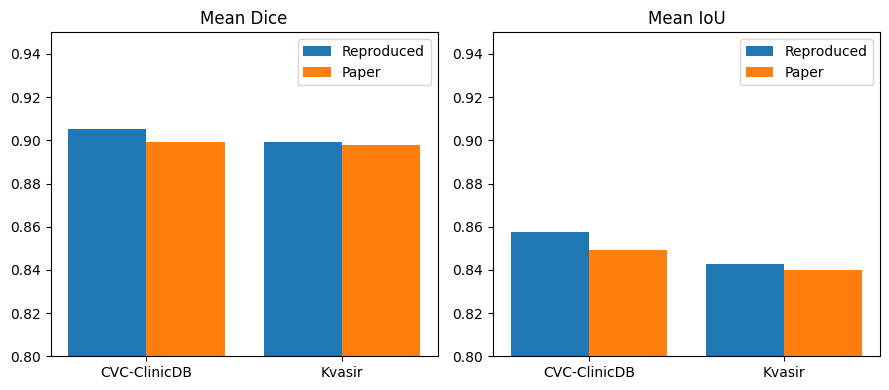

In [43]:
import numpy as np
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, metric in zip(ax, ['Dice', 'IoU']):
    x = np.arange(len(table))
    a.bar(x - 0.2, table[f'{metric} (reproduced)'], 0.4, label='Reproduced')
    a.bar(x + 0.2, table[f'{metric} (paper)'],      0.4, label='Paper')
    a.set_xticks(x); a.set_xticklabels(table.index)
    a.set_ylim(0.8, 0.95); a.set_title(f'Mean {metric}'); a.legend()
plt.tight_layout()
plt.savefig(f'{out}/pranet_vs_paper.png', dpi=200, bbox_inches='tight')
plt.show()

In [44]:
from google.colab import files
for f in os.listdir(out):
    files.download(f'{out}/{f}')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>